In [ ]:
from src.gaussian_mixture import GaussianMixtureMAR
from MARv2.src.data_generator import DataGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

In [5]:
eps_vals = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]

In [6]:
dg

NameError: name 'dg' is not defined

In [7]:
n = 2000
d = 3
kk = (1, 20)

In [8]:
k=10
mu0 = torch.rand((k, d)) * 2 - 1 # [-1, 1]
sigma0 = torch.rand((k, d)) * 2 # (0, 2)
pi0 = torch.rand(k) + 0.1
pi0 = pi0 / pi0.sum()

In [9]:
dg = DataGenerator('gaussian_mixture', mu=mu0, sigma=sigma0, pi=pi0)

In [115]:
def run_gaussian_mixture(dg, eps):
    X, M = dg.generate_eps_MNAR(eps, n, d)
    Xtest = dg.sample_truth(n, d)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [116]:
def run_normal(dg, eps):
    X, M = dg.generate_eps_MNAR(eps, n, d)
    Xtest = dg.sample_truth(n, d)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    q1 = np.quantile(Xtilde[:,0], 0.1).item()
    return ed, ds, q1

In [ ]:
def run_old(dg, eps, m=20):
    X, M = dg.generate_eps_MNAR(eps, n, d)
    Xtest = [dg.sample_truth(n, d) for _ in range(m)]
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = [gmm.sample(n)[0] for _ in range(m)]
    ed = [energy_distance(Xtest[i], Xtilde[i]).item() for i in range(m)]
    ds = [gmm.evaluate(Xtest[i]).item() for i in range(m)]
    return ed, ds

In [117]:
n_runs = 20

In [118]:
results = Parallel(n_jobs=-1)( 
    delayed(run_gaussian_mixture)(dg, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

  k=8 -> score=17134.8457
  k=8 -> score=17347.3418
  k=8 -> score=17264.9648
  k=8 -> score=16869.6621
  k=8 -> score=17420.1211
  k=8 -> score=17130.4844
  k=8 -> score=17401.2910
  k=8 -> score=17219.5215
  k=8 -> score=17212.6309
  k=8 -> score=17214.0840
  k=8 -> score=17305.9531
  k=8 -> score=17204.0645
  k=8 -> score=17224.2891
  k=8 -> score=17369.1641
  k=8 -> score=17413.2598
  k=8 -> score=17330.4043
  k=8 -> score=17227.4238
  k=8 -> score=17254.4805
  k=13 -> score=17137.2578
  k=13 -> score=16717.0840
  k=13 -> score=17343.8242
  k=13 -> score=17252.9590
  k=13 -> score=17128.7305
  k=13 -> score=17469.8027
  k=13 -> score=17353.0840
  k=13 -> score=17167.6777
  k=13 -> score=17414.0273
  k=13 -> score=17147.3652
  k=13 -> score=17218.3125
  k=13 -> score=17156.4180
  k=13 -> score=17416.7891
  k=13 -> score=17275.9160
  k=13 -> score=17252.0117
  k=13 -> score=17255.7148
  k=13 -> score=17216.9648
  k=13 -> score=17233.0840
  k=6 -> score=17182.5332
  k=6 -> score=17222

In [119]:
res = np.array(results).reshape(n_runs, len(eps_vals), 2)

In [140]:
def plot(res, eps):

    color = '#90be6d'

    _, _, m = res.shape
    fig, axes = plt.subplots(1, m, figsize=(14, 4))

    ylabs = ['energy distance', 'density score', 'quantile 0.1']

    for i, ax in enumerate(axes):

        ax.grid(
            True,
            linestyle='--',
            alpha=0.5
        )

        bp = ax.boxplot(
            res[:, :, i],
            patch_artist=True,
            showfliers=False,
            widths=0.3
        )

        ax.set_xticks(
            range(1, len(eps) + 1),
            eps,
            fontsize=11
        )

        ax.set_ylabel(ylabs[i])

        ax.set_xlabel(r'$\epsilon$')

        for patch in bp['boxes']:
            patch.set_facecolor(color)
            patch.set_alpha(0.7)

        # Reference line for subplot 3
        if i == 2:
            ax.axhline(
                #y=-1.282,
                y=-2.197,
                linestyle='--',
                linewidth=1.5
            )

    plt.tight_layout()
    plt.show()

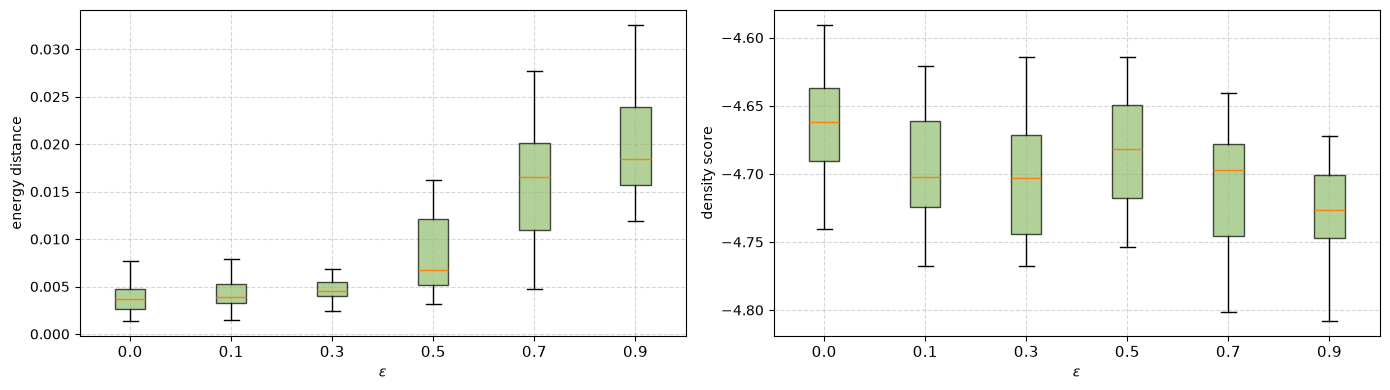

In [126]:
plot(res, eps_vals)

In [132]:
dgn = DataGenerator('Normal')
results_n = Parallel(n_jobs=-1)( 
    delayed(run_normal)(dgn, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

  k=8 -> score=15527.5420
  k=8 -> score=15379.7627
  k=8 -> score=15446.1826
  k=8 -> score=15550.4883
  k=8 -> score=15525.9463
  k=8 -> score=15504.5137
  k=8 -> score=15538.0742
  k=8 -> score=15544.1650
  k=8 -> score=15377.8105
  k=8 -> score=15411.0010
  k=8 -> score=15312.1182
  k=8 -> score=15383.1973
  k=8 -> score=15471.9492
  k=8 -> score=15212.9658
  k=8 -> score=15432.5381
  k=8 -> score=15592.3965
  k=8 -> score=15415.4160
  k=8 -> score=15615.8340
  k=13 -> score=15588.2539
  k=13 -> score=15695.4043
  k=13 -> score=15661.9355
  k=13 -> score=15651.3770
  k=13 -> score=15599.8945
  k=13 -> score=15671.9492
  k=13 -> score=15513.3730
  k=13 -> score=15640.2754
  k=13 -> score=15516.8242
  k=13 -> score=15719.5996
  k=13 -> score=15747.7891
  k=13 -> score=15676.7793
  k=13 -> score=15542.4395
  k=13 -> score=15350.3125
  k=13 -> score=15455.1074
  k=13 -> score=15531.1680
  k=13 -> score=15526.5254
  k=13 -> score=15569.7109
  k=6 -> score=15473.3438
  k=6 -> score=15482

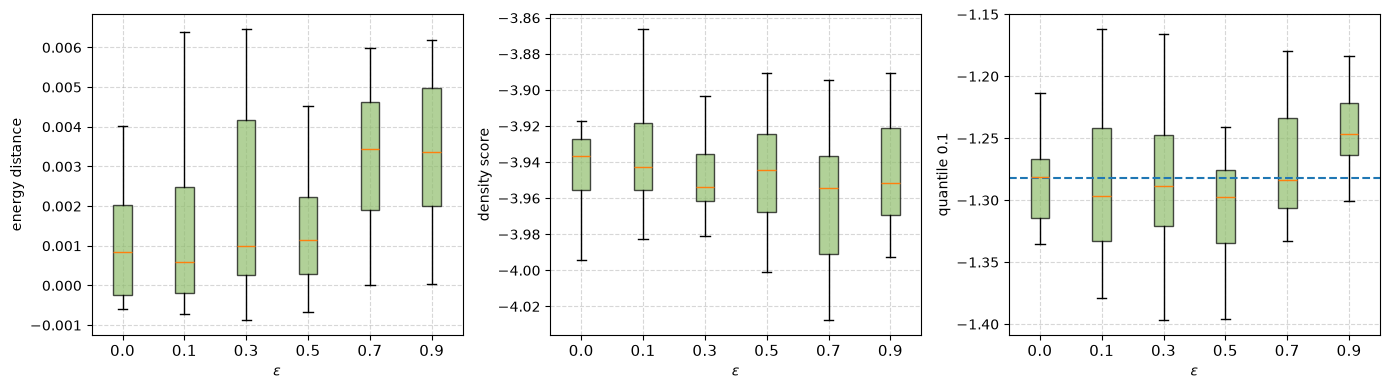

In [136]:
res_n = np.array(results_n).reshape(n_runs, len(eps_vals), 3)
plot(res_n, eps_vals)

In [138]:
dgl = DataGenerator('Logistic')
results_l = Parallel(n_jobs=-1)( 
    delayed(run_normal)(dgl, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

  k=8 -> score=20829.1895
  k=8 -> score=20834.4316
  k=8 -> score=20804.4688
  k=8 -> score=20823.9883
  k=8 -> score=20778.9746
  k=8 -> score=20938.1699
  k=8 -> score=21045.2715
  k=8 -> score=20920.2910
  k=8 -> score=21053.9121
  k=8 -> score=20957.2422
  k=8 -> score=21065.2266
  k=8 -> score=20945.4199
  k=8 -> score=20654.5977
  k=8 -> score=20820.2441
  k=8 -> score=20787.1602
  k=8 -> score=20984.6973
  k=8 -> score=20911.8691
  k=8 -> score=20797.3496
  k=13 -> score=20899.0156
  k=13 -> score=20906.7383
  k=13 -> score=20930.3125
  k=13 -> score=20950.3242
  k=13 -> score=21114.7930
  k=13 -> score=20880.4629
  k=13 -> score=21164.0977
  k=13 -> score=21009.4141
  k=13 -> score=21053.3398
  k=13 -> score=20955.1094
  k=13 -> score=20992.3809
  k=13 -> score=21093.6328
  k=13 -> score=21168.3555
  k=13 -> score=20934.9492
  k=13 -> score=21064.2441
  k=13 -> score=20783.0098
  k=13 -> score=21035.4297
  k=13 -> score=20906.0430
  k=6 -> score=20740.7578
  k=6 -> score=20787

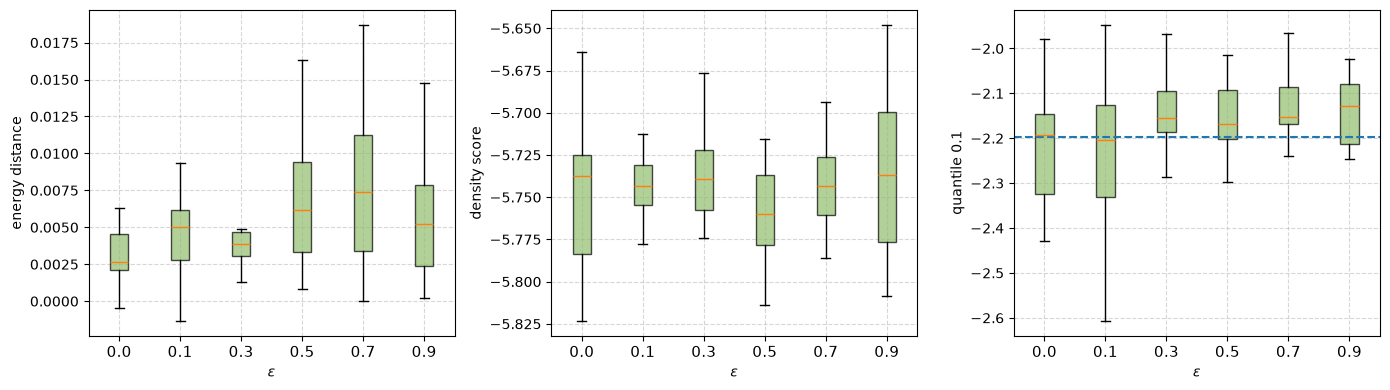

In [141]:
res_l = np.array(results_l).reshape(n_runs, len(eps_vals), 3)
plot(res_l, eps_vals)